# Exercise 2: Text Generation with Recurrent Neural Networks (LSTM, GRU)

## Introduction

In this exercise, we will explore the use of LSTM and GRU models for language modeling and text generation. You will implement both character-based and word-based text generation tasks, using the TED2013 dataset.

## Tasks

### Task 1: Prepare the Corpus
1. Load the text corpus `TED2013.ar-en.en` and perform the following preprocessing steps:
   - Convert all text to lowercase.
   - Remove any special characters or punctuation marks.
   
2. Prepare the corpus for both character-based and word-based text generation:
   - For both cases, create sequences of fixed length.
   - Generate input-output pairs for training the models.

### Task 2: Build the RNN Language Models (LM)
1. Create a character-based language model using Keras and TensorFlow, and train it on the preprocessed corpus.
   
2. Similarly, create a word-based language model using Keras and TensorFlow, and train it as well.

3. Generate text from a given seed:
   - First, use the character-based model to generate text.
   - Then, use the word-based model to generate text.


### Extra Work (Optional): Experimenting with Temperature

In this task, experiment with different temperature values and observe how the generated text changes. Use a character-level and a word-level language model to generate text from a given seed, and test different temperatures such as 0.5, 1.0, and 2.0.

# Temperature in Text Generation

**Temperature** is a hyperparameter used in the sampling process during text generation that controls the randomness or creativity of the predictions made by the model. It directly affects the probability distribution from which the next token (character or word) is sampled.

### How Temperature Works

1. **Logits - The Raw Model Outputs**:  
   The model outputs a set of *logits*, which are raw scores representing the relative likelihood of each token being the next one in a sequence. These logits are unnormalized and must be processed to derive a probability distribution.

2. **Scaling the Logits with Temperature**:  
   To adjust the model's behavior, we apply a *temperature* parameter during sampling. The temperature scales the logits before converting them into probabilities using the softmax function. This is represented mathematically as:

   $$ \text{adjusted_logits}_i = \frac{\text{logits}_i}{T} $$

   Here:
   - $T$ is the temperature.
   - When $T=1$, the logits remain unchanged.
   - When $T<1$, the logits are magnified, making high values relatively higher and low values relatively lower.
   - When $T>1$, the logits are compressed, reducing the differences between high and low values.

3. **Converting Logits to Probabilities**:  
   After scaling the logits, we apply the softmax function to convert them into probabilities. The softmax function normalizes the logits into a probability distribution:

   $$ p_i = \frac{e^{\frac{\text{logits}_i}{T}}}{\sum_{j=1}^n e^{\frac{\text{logits}_j}{T}}} $$

   This formula ensures the resulting probabilities sum to 1.

4. **Effect of Temperature**:
   - **Low Temperature ($T < 1$)**:  
     Lowering the temperature magnifies the differences between logits, making the probability distribution more concentrated. This leads to more deterministic and repetitive text generation, as the model strongly favors the most probable tokens.
   - **High Temperature ($T > 1$)**:  
     Increasing the temperature compresses the logits, resulting in a more uniform probability distribution. This increases the chances of selecting less probable tokens, leading to more diverse and creative text but with a greater risk of incoherence.






In [1]:
!apt-get install unrar
!unrar x Lab7_data.rar
!ls

'apt-get' is not recognized as an internal or external command,
operable program or batch file.
'unrar' is not recognized as an internal or external command,
operable program or batch file.
'ls' is not recognized as an internal or external command,
operable program or batch file.


In [2]:
!pip install nltk
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Rosey\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Rosey\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

Total sentences: 170201
Avg length: 17.45


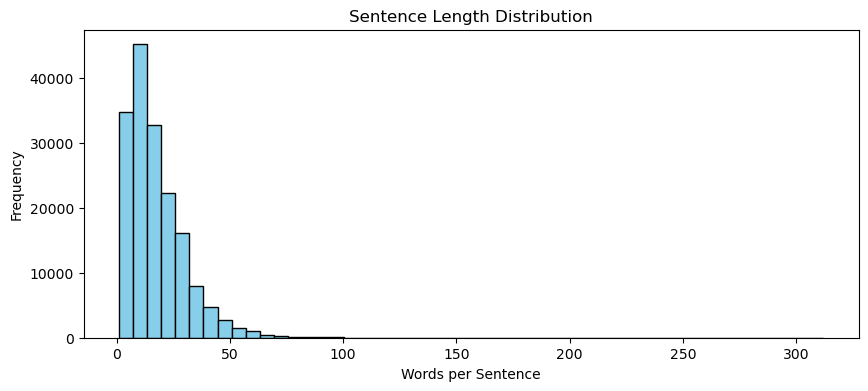

In [3]:
# =======================================================
# 1. IMPORTS
# =======================================================

import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Embedding, Dropout
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.optimizers import Adam

import re
import matplotlib.pyplot as plt
import os
import nltk  # Needed for sentence tokenization


# =======================================================
# 2. MODEL & DATA CONFIGURATION
# =======================================================

MAX_VOCAB_SIZE = 5000     # Maximum vocabulary size (top-N most frequent words)
EMBEDDING_DIM = 50        # Output dimensionality of word embeddings
LSTM_UNITS = 128          # Number of units in LSTM layer
DROPOUT_RATE = 0.2        # Dropout for regularization in the model


# =======================================================
# 3. TEXT CORPUS LOADING + CLEANING FUNCTION
# =======================================================

def load_text_corpus(file_path):
    """
    Load a text corpus from a file and preprocess it for NLP tasks.

    Steps:
    1. Read file and convert all text to lowercase.
    2. Remove URLs.
    3. Add spacing around basic punctuation (.,!?).
    4. Remove unwanted characters, keeping only letters, digits, and punctuation.
    5. Collapse extra whitespace.
    6. Sentence tokenize the cleaned text.

    Parameters:
        file_path (str): Path to the text dataset.

    Returns:
        tuple:
            - preprocessed_text (str): Entire cleaned text corpus as one string.
            - sentences_tok (list): List of individual sentences.
    """
    # ------------------------------------------------------
    # Read entire file
    # ------------------------------------------------------
    with open(file_path, 'r', encoding='utf-8') as file:
        text = file.read().lower()

    # ------------------------------------------------------
    # Remove URLs
    # ------------------------------------------------------
    text = re.sub(r'https?://\S+|www\.\S+', '', text)

    # ------------------------------------------------------
    # Add spaces around punctuation (important for tokenization)
    # ------------------------------------------------------
    text = re.sub(r"([.,!?])", r" \1 ", text)

    # ------------------------------------------------------
    # Remove all characters except alphanumeric + .,!?
    # ------------------------------------------------------
    text = re.sub(r"[^a-zA-Z0-9.,!?]+", " ", text)

    # ------------------------------------------------------
    # Collapse multiple spaces to a single space
    # ------------------------------------------------------
    preprocessed_text = " ".join(text.split())

    # ------------------------------------------------------
    # Tokenize into sentences
    # ------------------------------------------------------
    sentences_tok = nltk.tokenize.sent_tokenize(preprocessed_text)

    return preprocessed_text, sentences_tok



# =======================================================
# 4. BASIC SENTENCE LENGTH STATISTICS + HISTOGRAM
# =======================================================

def plot_sentence_length_stats(sentences):
    """
    Compute and display statistics about sentence lengths in the corpus.

    Parameters:
        sentences (list): List of sentence strings.

    Prints:
        - Total number of sentences
        - Average sentence length (# words)

    Displays:
        - Histogram of sentence lengths
    """
    # Compute sentence lengths (word counts)
    sentence_lengths = [len(sentence.split()) for sentence in sentences]

    # Print statistics
    print(f"Total sentences: {len(sentences)}")
    print(f"Avg length: {sum(sentence_lengths) / len(sentence_lengths):.2f}")

    # Plot histogram
    plt.figure(figsize=(10, 4))
    plt.hist(sentence_lengths, bins=50, color='skyblue', edgecolor='black')
    plt.title("Sentence Length Distribution")
    plt.xlabel("Words per Sentence")
    plt.ylabel("Frequency")
    plt.show()



# =======================================================
# 5. EXECUTION: LOAD OR CREATE CORPUS & DISPLAY STATS
# =======================================================

file_path = "TED2013.ar-en.en"

# If dataset is missing (common in notebook setups), create temporary dummy corpus
if not os.path.exists(file_path):
    print("Warning: Dataset not found. Creating dummy data for demonstration.")
    with open(file_path, "w") as f:
        f.write("this is a test sentence for the model. " * 5000)

# Load dataset and preprocess text
preprocessed_text, sentences_tok = load_text_corpus(file_path)

# Plot sentence length statistics to inspect corpus structure
plot_sentence_length_stats(sentences_tok)

In [4]:
# ================================================================
# 1. CHARACTER-LEVEL SEQUENCE GENERATION
# ================================================================

import numpy as np
from tensorflow.keras.preprocessing.text import Tokenizer

def create_char_level_sequences(text, sequence_length=50, max_chars=400000):
    """
    Create character-level training sequences for next-character prediction
    (a basic character-level language model).

    This function prepares the data by tokenizing the corpus into character IDs,
    creating fixed-length input sequences (X), and extracting the single subsequent
    character (y) as the target for prediction.

    Parameters:
        text (str): The entire input corpus (e.g., a book or large text file).
        sequence_length (int): The length of each input sequence (the context window).
                               The model will try to predict the (sequence_length + 1)th character.
        max_chars (int): Maximum number of characters to process from the corpus.
                         Used to prevent excessive memory usage (RAM overload).

    Returns:
        tuple:
            - X (np.array): Encoded input sequences. Shape is (number_of_samples, sequence_length).
            - y (np.array): Encoded next-character targets. Shape is (number_of_samples,).
            - tokenizer_chars (Tokenizer): The fitted char-level tokenizer, necessary
                                           for decoding predictions and one-hot encoding targets later.
    """

    # ------------------------------------------------------------
    ## 1. Corpus Truncation
    # ------------------------------------------------------------
    # Limit the input text length to the defined maximum number of characters.
    # This is a crucial step for large corpora to ensure the resulting arrays
    # (X and y) do not exceed available memory, especially when training on limited resources.
    text = text[:max_chars]

    # ------------------------------------------------------------
    ## 2. Character-Level Tokenization
    # ------------------------------------------------------------
    # Initialize the Keras Tokenizer in character-level mode (`char_level=True`).
    # This means the tokenizer will treat every individual character (including spaces,
    # punctuation, and newline characters) as a unique token.
    tokenizer_chars = Tokenizer(char_level=True)

    # Fit the tokenizer on the corpus. This step builds the vocabulary (char -> ID mapping).
    # The vocabulary size (vocab_size) will be `len(tokenizer_chars.word_index) + 1`.
    tokenizer_chars.fit_on_texts([text])

    # Initialize lists to hold the sequence inputs and the corresponding targets.
    sequences = []
    next_chars = []

    # Step size defines how many characters to skip between the start of consecutive sequences.
    # Using `step < sequence_length` creates **overlapping sequences**, which increases the
    # amount of training data and exposes the model to more context variations.
    step = 3 # A common value to balance data augmentation and sequence redundancy.

    # ------------------------------------------------------------
    ## 3. Creating Overlapping Sequences
    # ------------------------------------------------------------
    # Iterate through the text, extracting input sequences (X) and next-character targets (y).
    # The loop stops just before the remaining text length is less than `sequence_length + 1`
    # (input sequence + the target character).
    for i in range(0, len(text) - sequence_length, step):
        sequences.append(text[i:i + sequence_length])
        next_chars.append(text[i + sequence_length])
    

    # ------------------------------------------------------------
    ## 4. Encoding Characters to Integer IDs
    # ------------------------------------------------------------
    # Use the fitted tokenizer to convert the lists of character strings into lists of integer IDs.

    # `X`: Convert list of input sequences into a list of lists of integer IDs.


    # `y`: Convert list of target characters into a list of integer IDs.
    # Note: `texts_to_sequences` returns a list of lists, even for single characters.
    X = tokenizer_chars.texts_to_sequences(sequences)
    y = tokenizer_chars.texts_to_sequences(next_chars)
    

    # ------------------------------------------------------------
    ## 5. Final Array Conversion
    # ------------------------------------------------------------
    # Convert the list of encoded sequences (X) into a NumPy array.


    # Convert the list of encoded targets (y) into a NumPy array and flatten it.
    # Flattening changes the shape from (num_samples, 1) to (num_samples,).


    # The returned X, y, and tokenizer are ready for building an embedding layer,
    # a recurrent network (like LSTM), and subsequent one-hot encoding of the targets (y).
    X_chars = np.array(X)
    y_chars = np.array(y).flatten()
    return X_chars, y_chars, tokenizer_chars


# Generate character-level dataset
X_chars, y_chars, tokenizer_chars = create_char_level_sequences(preprocessed_text)
print(f"Char Shape: {X_chars.shape}")



# ================================================================
# 2. WORD-LEVEL SEQUENCE GENERATION (WITH MEMORY-SAFE FIXES)
# ================================================================

def create_word_level_sequences(sentences, sequence_length=10, max_sentences=200000):
    """
    Create word-level next-word prediction sequences.

    Major Fixes Implemented:
        - Vocabulary is limited using `num_words=MAX_VOCAB_SIZE`.
        - OOV tokens are handled safely with <unk>.
        - Sequences stored as int32 to reduce memory use.
        - Caps number of sentences to prevent RAM overflow.

    Steps:
        1. Fit word tokenizer on the sentence list.
        2. Convert each sentence into integer tokens.
        3. Generate sliding windows of length `sequence_length`.
        4. Store the following word as target.

    Parameters:
        sentences (list): Tokenized list of text sentences.
        sequence_length (int): Input window size for training.
        max_sentences (int): Maximum number of sentences to process.

    Returns:
        tuple:
            - X_words (np.array): Word-level sequences (int32).
            - y_words (np.array): Next-word targets (int32).
            - tokenizer_words (Tokenizer): Fitted tokenizer.
    """
    # ------------------------------------------------------------
    # Prevent memory overload
    # ------------------------------------------------------------
    # Truncate the input sentence list to the defined maximum count.
    sentences = sentences[:max_sentences]

    # ------------------------------------------------------------
    # Word tokenizer with controlled vocabulary size
    # ------------------------------------------------------------
    tokenizer_words = Tokenizer(
        # Limit the vocabulary size to include only the most frequent words.
        num_words=MAX_VOCAB_SIZE,
        # Designate a token for Out-of-Vocabulary words. This is mapped to a specific index (usually 1).
        oov_token="<unk>"
    )
    # Fit the tokenizer on the corpus to build the vocabulary (word -> ID mapping) and handle OOV.
    tokenizer_words.fit_on_texts(sentences)

    input_sequences = [] # List to accumulate the input sliding windows (X).
    targets = []         # List to accumulate the next word targets (y).

    # ------------------------------------------------------------
    # Build word sequences (Sliding Window Mechanism) 🪟
    # ------------------------------------------------------------
    for sentence in sentences:
        # Convert the current sentence string into a sequence of integer IDs using the fitted tokenizer.
        # [0] is used because texts_to_sequences returns a list of lists (one list per sentence).
        token_list = tokenizer_words.texts_to_sequences([sentence])[0]
        # Require enough words for a full window: sequence_length (input) + 1 (target).
        
        if len(token_list) > sequence_length:
        # Iterate through the token list to create overlapping sliding windows.
            # The loop runs until the start index 'i' is `sequence_length` words away from the end.
                # Input sequence (X): Slice the token list to get the context window of length `sequence_length`.
                # Target word (y): The word immediately following the input sequence (the word at index `i + sequence_length`).
            for i in range(len(token_list) - sequence_length):
                input_seq = token_list[i:i + sequence_length]
                target = token_list[i + sequence_length]
                input_sequences.append(input_seq)
                targets.append(target)
    

    # ------------------------------------------------------------
    # Convert to arrays using int32 (Memory Optimization)
    # ------------------------------------------------------------
    # Convert the list of integer sequences into a NumPy array with 32-bit integers.
    # This choice of dtype is sufficient for word indices and significantly reduces RAM usage
    # compared to the default 64-bit float/integer types.
    X_words = np.array(input_sequences, dtype=np.int32)
    # Convert the list of integer targets into a NumPy array with 32-bit integers.
    y_words = np.array(targets, dtype=np.int32)

    # Return the prepared dataset and the tokenizer object.
    return X_words, y_words, tokenizer_words


# Generate word-level dataset
# Call the function using the assumed global variable 'sentences_tok'.
X_words, y_words, tokenizer_words = create_word_level_sequences(sentences_tok)
# Print the shape of the resulting input array to confirm the number of samples and sequence length.
print(f"Word Shape: {X_words.shape}")


Char Shape: (133317, 50)
Word Shape: (1191286, 10)


In [5]:
# =====================================================================
# 3. MODEL BUILDING (WITH STABLE OPTIMIZERS + GRADIENT CLIPPING)
# =====================================================================

def build_char_level_model(sequence_length, vocab_size, units=128):
    """
    Build a character-level LSTM model for next-character prediction.

    Architecture:
        - Embedding layer
        - LSTM → Dropout → LSTM → Dropout
        - Softmax output over full character vocabulary

    Key Fixes:
        - Uses Adam optimizer with clipnorm=1.0 to prevent exploding gradients.
        - Uses dropout for generalization.

    Parameters:
        sequence_length (int): Input sequence length.
        vocab_size (int): Number of unique characters.
        units (int): Number of LSTM units (default: 128).

    Returns:
        keras.Model: Compiled char-level model.
    """

    model = Sequential([
        Embedding(input_dim=vocab_size, output_dim=EMBEDDING_DIM, input_length=sequence_length),
        LSTM(units, return_sequences=True, dropout=DROPOUT_RATE),
        Dropout(DROPOUT_RATE),
        LSTM(units, dropout=DROPOUT_RATE),
        Dropout(DROPOUT_RATE),
        Dense(vocab_size, activation='softmax')
    ])

    # Stable training with gradient clipping
    optimizer = Adam(learning_rate=0.0001, clipnorm=1.0)

    model.compile(
        loss='sparse_categorical_crossentropy',
        optimizer=optimizer,
        metrics=['accuracy']
    )

    return model



def build_word_level_model(sequence_length, vocab_size, units=128):
    """
    Build a word-level LSTM model for next-word prediction.

    Architecture:
        - Word embedding layer (EMBEDDING_DIM defined earlier)
        - LSTM → Dropout → LSTM → Dropout
        - Dense softmax output over vocabulary

    Key Fixes:
        - Vocabulary limited using Tokenizer num_words.
        - Gradient clipping stabilizes next-word training.
        - Higher dropout than char model (word models overfit easier).

    Parameters:
        sequence_length (int): Input sequence length.
        vocab_size (int): Limited vocabulary size.
        units (int): Number of LSTM units.

    Returns:
        keras.Model: Compiled model.
    """

    model = Sequential([
        Embedding(input_dim=vocab_size, output_dim=EMBEDDING_DIM, input_length=sequence_length),
        LSTM(units, return_sequences=True, dropout=DROPOUT_RATE),
        Dropout(DROPOUT_RATE),
        LSTM(units, dropout=DROPOUT_RATE),
        Dropout(DROPOUT_RATE),
        Dense(vocab_size, activation='softmax')
    ])
    

    optimizer = Adam(learning_rate=0.0001, clipnorm=1.0)

    model.compile(
        loss='sparse_categorical_crossentropy',
        optimizer=optimizer,
        metrics=['accuracy']
    )

    return model



# =====================================================================
# 4. TRAIN CHARACTER-LEVEL MODEL
# =====================================================================

print("\nTraining Character-Level Model...")

char_vocab_size = len(tokenizer_chars.word_index) + 1
char_sequence_length = X_chars.shape[1]

char_model = build_char_level_model(
    sequence_length=char_sequence_length,
    vocab_size=char_vocab_size
)

char_model.fit(
    X_chars,
    y_chars,
    epochs=10,
    batch_size=128,
    validation_split=0.1
)



# =====================================================================
# 5. TRAIN WORD-LEVEL MODEL
# =====================================================================

print("\nTraining Word-Level Model...")

# Ensure vocabulary passed to model matches Tokenizer limit
word_vocab_size = min(len(tokenizer_words.word_index) + 1, MAX_VOCAB_SIZE)
word_sequence_length = X_words.shape[1]

word_model = build_word_level_model(
    sequence_length=word_sequence_length,
    vocab_size=word_vocab_size
)

word_model.fit(
    X_words,
    y_words,
    epochs=5,
    batch_size=128,
    validation_split=0.1
)



Training Character-Level Model...
Epoch 1/10


c:\Users\Rosey\anaconda3\envs\NLP\Lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


938/938 ━━━━━━━━━━━━━━━━━━━━ 132s 138ms/step - accuracy: 0.2047 - loss: 2.9797 - val_accuracy: 0.1997 - val_loss: 2.8890
Epoch 2/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 121s 129ms/step - accuracy: 0.2259 - loss: 2.8091 - val_accuracy: 0.2357 - val_loss: 2.6681
Epoch 3/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 125s 133ms/step - accuracy: 0.2672 - loss: 2.6079 - val_accuracy: 0.2918 - val_loss: 2.5025
Epoch 4/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 128s 137ms/step - accuracy: 0.3007 - loss: 2.4547 - val_accuracy: 0.3105 - val_loss: 2.4005
Epoch 5/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 132s 141ms/step - accuracy: 0.3121 - loss: 2.3852 - val_accuracy: 0.3190 - val_loss: 2.3512
Epoch 6/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 130s 139ms/step - accuracy: 0.3204 - loss: 2.3448 - val_accuracy: 0.3230 - val_loss: 2.3125
Epoch 7/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 130s 139ms/step - accuracy: 0.3275 - loss: 2.3094 - val_accuracy: 0.3296 - val_loss: 2.2790
Epoch 8/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 144s 154ms/step - accuracy: 0.3331 - loss: 2.28

In [6]:
# =====================================================================
# 4. TEXT GENERATION (CHAR-LEVEL OR WORD-LEVEL)
# =====================================================================

def generate_text(model, tokenizer, seed_text, is_char_level=True,
                  next_tokens=50, temperature=1.0):
    """
    Generate text using a trained LSTM model (either char-level or word-level).

    This function:
        1. Tokenizes the seed text
        2. Predicts the next character/word repeatedly
        3. Applies temperature-based sampling
        4. Ensures '<unk>' and padding tokens are never generated
        5. Builds the generated sequence step-by-step

    Parameters:
    ----------
    model (keras.Model):
        Trained character-level or word-level LSTM model.
    tokenizer (Tokenizer):
        Fitted Keras tokenizer for characters or words.
    seed_text (str):
        Starting text used to begin generation.
    is_char_level (bool):
        If True → character-level generation.
        If False → word-level generation.
    next_tokens (int):
        Number of characters/words to generate.
    temperature (float):
        Controls creativity:
            - Low temp (0.2–0.5) = predictable, safe text
            - Medium temp (0.7) = balanced
            - High temp (1.0–1.5) = creative, chaotic

    Returns:
    --------
    str:
        The concatenated generated text.

    Notes:
    ------
    - The model has a fixed input length.
    - We always pad/truncate the seed to match this length.
    - <unk> tokens and padding (0 index) are suppressed to reduce garbage output.
    """

    # ==============================================================
    # 1. Model input length (fixed at training time)
    # ==============================================================
    input_len = model.input_shape[1]

    output_text = seed_text           # Final text returned
    current_text = seed_text          # Rolling window of last N tokens

    # Lookup <unk> (if exists)
    oov_index = tokenizer.word_index.get('<unk>')

    # ==============================================================
    # 2. Generate tokens one at a time
    # ==============================================================
    for _ in range(next_tokens):

        # ----------------------------------------------------------
        # (A) Convert current text → numerical tokens
        # ----------------------------------------------------------
        if is_char_level:
            token_list = tokenizer.texts_to_sequences([current_text])[0]
        else:
            token_list = tokenizer.texts_to_sequences([current_text])[0]
        
        
        # Pad/Truncate to match model input length
        token_list = pad_sequences([token_list], maxlen=input_len, padding='pre')[0]

        try:
            # ------------------------------------------------------
            # (B) Get model's probability distribution for next token
            # ------------------------------------------------------
            predictions = model.predict(np.array([token_list]), verbose=0)[0]

            # ------------------------------------------------------
            # (C) Suppress invalid tokens:
            #     - Padding index = 0
            #     - <unk> token
            # ------------------------------------------------------
            # Never generate padding
            # Suppress unknown token
            # ------------------------------------------------------
            # (D) Re-normalize the probability distribution
            # ------------------------------------------------------
            # Avoid division by zero; generation stops

            predictions[0] = 0
            if oov_index:
                predictions[oov_index] = 0
            
            if predictions.sum() == 0:
                break
            
            predictions = predictions / predictions.sum()
            
            # ------------------------------------------------------
            # (E) Apply temperature scaling
            # ------------------------------------------------------

            # Softmax after scaling


            # ------------------------------------------------------
            # (F) Random sampling from distribution
            # ------------------------------------------------------

            # Safety fallback: ensure we don't pick index 0


            # ------------------------------------------------------
            # (G) Convert token → actual text
            # ------------------------------------------------------


            # ------------------------------------------------------
            # (H) Append to output and update rolling window
            # ------------------------------------------------------
            predictions = np.log(predictions + 1e-10) / temperature
            predictions = np.exp(predictions) / np.sum(np.exp(predictions))
            
            predicted_id = np.random.choice(len(predictions), p=predictions)
            
            if predicted_id == 0:
                break
            
            output_char = tokenizer.index_word.get(predicted_id, '')
            output_text += output_char if is_char_level else ' ' + output_char
            current_text = output_text if is_char_level else output_text.split()[-input_len:]
            if not is_char_level:
                current_text = ' '.join(current_text)
                
        except Exception as e:
            print(f"Generation stopped: {e}")
            break
    
    return output_text



# =====================================================================
# DEMO: GENERATE TEXT
# =====================================================================

seed_text = "he was eating"

print("\n--- Generated Text (Word-Level) ---")
print(generate_text(
    word_model,
    tokenizer_words,
    seed_text,
    is_char_level=False,
    temperature=0.7   # Best for word models
))

print("\n--- Generated Text (Char-Level) ---")
print(generate_text(
    char_model,
    tokenizer_chars,
    seed_text,
    is_char_level=True,
    next_tokens=200,
    temperature=0.7
))



--- Generated Text (Word-Level) ---
he was eating the world that is the little culture of a chinese story too the lot of the home of the world with a world to did the first of a last time that we can just are the end to see the disease is the changes in the planet and the

--- Generated Text (Char-Level) ---
he was eating . an y bont ind ant weuus , fou gerpe fot , and bunmin goce wass i w soad ge sory o dhort in . in in mantinll srot soce deverl . we who tis sove wot fat ir thas ind hoill if the rann af thas sin thes


In [7]:
# ===============================================================
# 5. MODEL EVALUATION: PERPLEXITY AND ACCURACY
# ===============================================================

import math

def calculate_perplexity(model, X_test, y_test):
    """
    Calculate the perplexity of a trained model efficiently.

    Perplexity is a common metric for language models:
        Perplexity = exp(CrossEntropyLoss)

    Lower perplexity = better predictive performance.

    Steps:
        1. Evaluate the model on test data to get the cross-entropy loss.
        2. Use exp(loss) to compute perplexity.

    Parameters:
    ----------
    model : keras.Model
        Trained character-level or word-level model.
    X_test : np.array
        Test sequences (inputs).
    y_test : np.array
        True targets corresponding to X_test.

    Returns:
    -------
    tuple:
        - perplexity (float): Exponential of the model's loss.
        - accuracy (float): Model accuracy on the test set.
    """
    print(f"Evaluating model on {len(X_test)} samples...")

    # ----------------------------------------------------------
    # 1. Evaluate model: returns [loss, accuracy]
    # ----------------------------------------------------------
    loss, accuracy = model.evaluate(X_test, y_test, verbose=0)

    # ----------------------------------------------------------
    # 2. Compute perplexity: exp(loss) for cross-entropy
    # ----------------------------------------------------------
    perplexity = math.exp(loss)

    return perplexity, accuracy



# ===============================================================
# 6. PREPARE TEST DATA (LAST 10% OF DATA)
# ===============================================================

# Use last 10% of sequences for testing
char_split = int(len(X_chars) * 0.9)
word_split = int(len(X_words) * 0.9)



# ===============================================================
# 7. CHARACTER-LEVEL EVALUATION
# ===============================================================
print("\n--- Character-Level Model Evaluation ---")
char_ppl, char_acc = calculate_perplexity(
    char_model,
    X_chars[char_split:],
    y_chars[char_split:]
)
print(f"Char Accuracy:  {char_acc*100:.2f}%")
print(f"Char Perplexity: {char_ppl:.2f}")
# Note: Char-level perplexity is usually low (1–10), because vocabulary is small (~50 chars)



# ===============================================================
# 8. WORD-LEVEL EVALUATION
# ===============================================================
print("\n--- Word-Level Model Evaluation ---")
word_ppl, word_acc = calculate_perplexity(
    word_model,
    X_words[word_split:],
    y_words[word_split:]
)
print(f"Word Accuracy:  {word_acc*100:.2f}%")
print(f"Word Perplexity: {word_ppl:.2f}")
# Note: Good word-level perplexity for simple LSTMs is typically between 50 and 200



--- Character-Level Model Evaluation ---
Evaluating model on 13332 samples...
Char Accuracy:  33.90%
Char Perplexity: 9.14

--- Word-Level Model Evaluation ---
Evaluating model on 119129 samples...
Word Accuracy:  13.92%
Word Perplexity: 226.55
